# Visual Model — Blind Predictions on Travel Clips

## Pipeline
1. Load calibrated model from `models/visual_accumulator_latest.json`
2. For each clip folder in `data/processed/frames/<clip_id>/`:
   - Load JPEG frames (saved by preprocess_data.py)
   - Load frame timestamps from `frame_times.npy`
   - Run frames through AlexNet fc7
   - Compute L2 distances between consecutive embeddings
   - Run accumulator → tick count
   - Apply calibration → predicted perceived duration
3. Save results to `results/visual/travel/`


In [1]:
# ============================================================================
# SECTION 1: Imports
# ============================================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from PIL import Image
from tqdm import tqdm

import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as T
from torchvision.models import alexnet, AlexNet_Weights

import matplotlib.pyplot as plt

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
print(torch.__version__)
print(torchvision.__version__)


PyTorch version: 2.4.1+cu121
CUDA available:  True
2.4.1+cu121
0.19.1+cu121


In [2]:
# ============================================================================
# SECTION 2: Load Calibrated Model
# ============================================================================

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR   = PROJECT_ROOT / "models"
FRAMES_DIR   = PROJECT_ROOT / "data" / "processed" / "frames"
OUT_DIR      = PROJECT_ROOT / "results" / "visual" / "travel"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load saved model artifact
model_path = MODELS_DIR / "visual_accumulator_latest.json"
assert model_path.exists(), f"Model not found: {model_path}. Run visual_model.ipynb first."

with open(model_path) as f:
    saved_model = json.load(f)

slope     = saved_model["calibration"]["slope"]
intercept = saved_model["calibration"]["intercept"]
ATTENTION  = saved_model["params"]["ATTENTION"]
EMA_ALPHA  = saved_model["params"]["EMA_ALPHA"]
THRESH_K   = saved_model["params"]["THRESH_K"]
REFRACTORY = saved_model["params"]["REFRACTORY"]
WARMUP     = saved_model["params"]["WARMUP"]

# Device
BATCH_SIZE = 64
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Model loaded:    {saved_model['name']}")
print(f"Created at:      {saved_model['created_at']}")
print(f"Calibration:     slope={slope:.4f}, intercept={intercept:.4f}")
print(f"Params:          ATTENTION={ATTENTION}, THRESH_K={THRESH_K}, WARMUP={WARMUP}")
print(f"Validation:      r={saved_model['metrics']['pearson_r_vs_human']:.3f}, "
      f"MAE={saved_model['metrics']['mae_vs_human']:.2f}s")
print(f"Device:          {device}")


Model loaded:    visual_accumulator_fc7
Created at:      2026-04-19T12:54:42
Calibration:     slope=0.4114, intercept=1.3200
Params:          ATTENTION=0.67, THRESH_K=1.6, WARMUP=10
Validation:      r=0.847, MAE=4.63s
Device:          cuda


In [3]:
# ============================================================================
# SECTION 3: Build AlexNet Feature Extractor
# (identical to visual_extract_alexnet.py)
# ============================================================================

def build_model(device):
    """AlexNet truncated at fc7 (4096-dim output)."""
    weights   = AlexNet_Weights.IMAGENET1K_V1
    net       = alexnet(weights=weights)
    extractor = nn.Sequential(
        net.features,
        net.avgpool,
        nn.Flatten(),
        net.classifier[0],       # fc6 linear
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.0),
        net.classifier[3],       # fc7 linear
        nn.ReLU(inplace=True),
    )
    extractor.eval().to(device)
    return extractor

def build_transform():
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD  = [0.229, 0.224, 0.225]
    return T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def compute_change(embeddings):
    """L2 and cosine distance between consecutive fc7 vectors."""
    n        = embeddings.shape[0]
    l2_dist  = np.zeros(n, dtype=np.float32)
    cos_dist = np.zeros(n, dtype=np.float32)
    if n <= 1:
        return l2_dist, cos_dist
    a    = embeddings[:-1]
    b    = embeddings[1:]
    diff = b - a
    l2_dist[1:]  = np.linalg.norm(diff, axis=1)
    a_norm  = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)
    b_norm  = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-8)
    cos_sim = np.sum(a_norm * b_norm, axis=1)
    cos_dist[1:] = 1.0 - np.clip(cos_sim, -1.0, 1.0)
    return l2_dist, cos_dist

alexnet_model = build_model(device)
transform     = build_transform()
print("AlexNet feature extractor ready")


AlexNet feature extractor ready


In [4]:
# ============================================================================
# SECTION 4: Accumulator Model
# (identical to visual_model.ipynb)
# ============================================================================

def accumulate_ticks(dist, attention, ema_alpha, thresh_k, refractory, warmup):
    x = (attention * np.asarray(dist, dtype=np.float32)).copy()
    if len(x) > 0 and x[0] == 0:
        x = x[1:]
    if len(x) <= warmup:
        return 0
    mu    = 0.0
    v     = 1e-6
    ticks = 0
    refr  = 0
    for t, xi in enumerate(x):
        xi        = float(xi)
        sigma     = float(np.sqrt(max(v, 1e-8)))
        threshold = mu + thresh_k * sigma
        if t >= warmup:
            if refr > 0:
                refr -= 1
            elif xi > threshold:
                ticks += 1
                refr   = int(refractory)
        prev_mu = mu
        mu = (1.0 - ema_alpha) * mu + ema_alpha * xi
        v  = (1.0 - ema_alpha) * v  + ema_alpha * (xi - prev_mu) * (xi - mu)
    return int(ticks)

print("Accumulator ready")


Accumulator ready


In [5]:
# ============================================================================
# SECTION 5: Run Full Pipeline on All Clip Folders
# Loads JPEGs → AlexNet fc7 → L2 distances → accumulator → calibration
# ============================================================================

clip_folders = sorted(
    [d for d in FRAMES_DIR.iterdir() if d.is_dir() and any(d.glob("frame_*.jpg"))],
    key=lambda d: int(d.name) if d.name.isdigit() else 0
)

print(f"Found {len(clip_folders)} clip folder(s) in {FRAMES_DIR}")
print("=" * 65)

results   = []
frames_dir_out = OUT_DIR / "frames"
frames_dir_out.mkdir(exist_ok=True)

for clip_folder in clip_folders:
    clip_id = clip_folder.name

    # Load frame JPEGs and timestamps
    frame_paths = sorted(clip_folder.glob("frame_*.jpg"))
    times_path  = clip_folder / "frame_times.npy"

    if len(frame_paths) == 0:
        print(f"  Clip {clip_id}: No frames found — skipping")
        continue

    if times_path.exists():
        times = np.load(str(times_path))
        # Align lengths if needed
        n = min(len(frame_paths), len(times))
        frame_paths = frame_paths[:n]
        times       = times[:n]
    else:
        # Estimate timestamps from frame count at 15fps (preprocess default)
        times = np.arange(len(frame_paths), dtype=np.float32) / 15.0

    duration_s = float(times[-1]) if len(times) > 0 else 0.0

    # Run AlexNet on all frames in batches
    all_embeddings = []
    with torch.no_grad():
        for i in range(0, len(frame_paths), BATCH_SIZE):
            batch_paths = frame_paths[i:i + BATCH_SIZE]
            imgs  = [transform(Image.open(p).convert("RGB")) for p in batch_paths]
            batch = torch.stack(imgs, 0).to(device)
            embs  = alexnet_model(batch).detach().cpu().numpy()
            all_embeddings.append(embs)

    embeddings = np.concatenate(all_embeddings, axis=0)

    # Compute L2 and cosine distances
    l2_dist, cos_dist = compute_change(embeddings)

    # Save per-frame metrics CSV
    frame_csv = frames_dir_out / f"{clip_id}_frames.csv"
    pd.DataFrame({
        "time_s":      times,
        "l2_to_prev":  l2_dist,
        "cos_to_prev": cos_dist,
    }).to_csv(frame_csv, index=False)

    # Run accumulator
    ticks = accumulate_ticks(l2_dist, ATTENTION, EMA_ALPHA, THRESH_K, REFRACTORY, WARMUP)

    # Apply calibration
    pred_s = slope * ticks + intercept

    results.append({
        "clip_id":          clip_id,
        "n_frames":         len(frame_paths),
        "duration_s":       round(duration_s, 2),
        "ticks":            ticks,
        "pred_perceived_s": round(float(pred_s), 3),
    })

    print(f"  Clip {clip_id:>3}: {len(frame_paths):>4} frames, "
          f"{duration_s:>5.1f}s actual → "
          f"{ticks:>4} ticks → "
          f"{pred_s:>6.2f}s predicted")

print("=" * 65)
print(f"Done. {len(results)} clips processed.")


Found 36 clip folder(s) in D:\Sahil\Capstone_Project\data\processed\frames
  Clip   1:  739 frames,  24.6s actual →   30 ticks →  13.66s predicted
  Clip   2:  720 frames,  24.0s actual →   46 ticks →  20.24s predicted
  Clip   3:  724 frames,  24.1s actual →   25 ticks →  11.60s predicted
  Clip   4:  798 frames,  26.6s actual →   47 ticks →  20.65s predicted
  Clip   5:  716 frames,  23.8s actual →   42 ticks →  18.60s predicted
  Clip   6:  738 frames,  24.6s actual →   38 ticks →  16.95s predicted
  Clip   7:  841 frames,  28.0s actual →   21 ticks →   9.96s predicted
  Clip   8:  792 frames,  26.4s actual →   42 ticks →  18.60s predicted
  Clip   9:  577 frames,  19.2s actual →   27 ticks →  12.43s predicted
  Clip  10:  684 frames,  22.8s actual →   29 ticks →  13.25s predicted
  Clip  11:  751 frames,  25.0s actual →   36 ticks →  16.13s predicted
  Clip  12:  656 frames,  21.8s actual →   29 ticks →  13.25s predicted
  Clip  13:  684 frames,  22.8s actual →   35 ticks →  15.72s

In [6]:
# ============================================================================
# SECTION 6: Save Results
# ============================================================================

results_df = pd.DataFrame(results)

# Main predictions CSV
out_csv = OUT_DIR / "travel_clip_predictions.csv"
results_df.to_csv(out_csv, index=False)
print(f"Predictions saved: {out_csv}")

# Metadata JSON
meta = {
    "model":      saved_model["name"],
    "created_at": saved_model["created_at"],
    "run_at":     datetime.now().isoformat(timespec="seconds"),
    "n_clips":    len(results_df),
    "calibration": saved_model["calibration"],
    "params":      saved_model["params"],
    "summary": {
        "mean_predicted_s": round(float(results_df["pred_perceived_s"].mean()), 2),
        "mean_actual_s":    round(float(results_df["duration_s"].mean()), 2),
        "mean_ticks":       round(float(results_df["ticks"].mean()), 2),
    }
}
with open(OUT_DIR / "travel_predictions_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# Display table
print()
print(f"{'Clip':>6} {'Actual (s)':>12} {'Ticks':>8} {'Predicted (s)':>15}")
print("-" * 45)
for _, row in results_df.iterrows():
    print(f"{row['clip_id']:>6} {row['duration_s']:>12.1f} "
          f"{int(row['ticks']):>8} "
          f"{row['pred_perceived_s']:>15.2f}")
print("-" * 45)
print(f"{'Mean':>6} {results_df['duration_s'].mean():>12.1f} "
      f"{results_df['ticks'].mean():>8.1f} "
      f"{results_df['pred_perceived_s'].mean():>15.2f}")


Predictions saved: D:\Sahil\Capstone_Project\results\visual\travel\travel_clip_predictions.csv

  Clip   Actual (s)    Ticks   Predicted (s)
---------------------------------------------
     1         24.6       30           13.66
     2         24.0       46           20.24
     3         24.1       25           11.60
     4         26.6       47           20.65
     5         23.8       42           18.60
     6         24.6       38           16.95
     7         28.0       21            9.96
     8         26.4       42           18.60
     9         19.2       27           12.43
    10         22.8       29           13.25
    11         25.0       36           16.13
    12         21.8       29           13.25
    13         22.8       35           15.72
    14         20.2       33           14.89
    15         17.7       10            5.43
    16         26.0       34           15.31
    17         22.0       38           16.95
    18         24.1       27           12.43
   

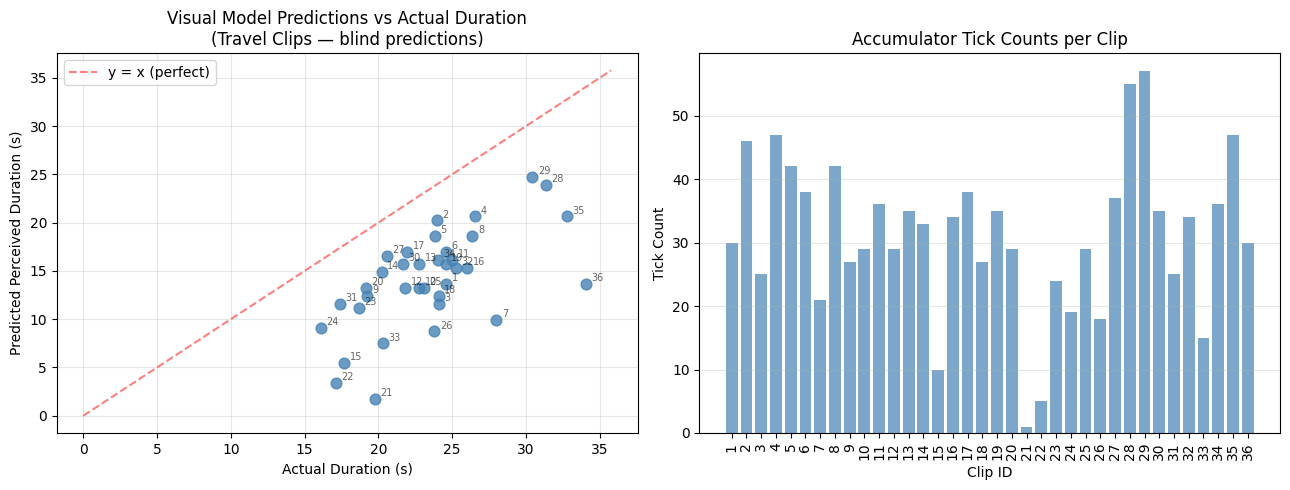

Plot saved: D:\Sahil\Capstone_Project\results\visual\travel\travel_clip_predictions.png


In [7]:
# ============================================================================
# SECTION 7: Visualisation
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Predicted vs actual duration
axes[0].scatter(results_df["duration_s"], results_df["pred_perceived_s"],
                color="steelblue", alpha=0.8, s=60, zorder=3)
max_val = max(results_df["duration_s"].max(), results_df["pred_perceived_s"].max()) * 1.05
axes[0].plot([0, max_val], [0, max_val], "r--", alpha=0.5, label="y = x (perfect)")
for _, row in results_df.iterrows():
    axes[0].annotate(str(row["clip_id"]),
                     (row["duration_s"], row["pred_perceived_s"]),
                     fontsize=7, alpha=0.6, textcoords="offset points", xytext=(4, 2))
axes[0].set_xlabel("Actual Duration (s)")
axes[0].set_ylabel("Predicted Perceived Duration (s)")
axes[0].set_title("Visual Model Predictions vs Actual Duration\n(Travel Clips — blind predictions)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Tick counts per clip
axes[1].bar(results_df["clip_id"].astype(str), results_df["ticks"],
            color="steelblue", alpha=0.7)
axes[1].set_xlabel("Clip ID")
axes[1].set_ylabel("Tick Count")
axes[1].set_title("Accumulator Tick Counts per Clip")
axes[1].tick_params(axis="x", rotation=90)
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUT_DIR / "travel_clip_predictions.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Plot saved: {OUT_DIR / 'travel_clip_predictions.png'}")


## Output Files

| File | Contents |
|---|---|
| `results/visual/travel/travel_clip_predictions.csv` | clip_id, duration_s, ticks, pred_perceived_s |
| `results/visual/travel/frames/<clip_id>_frames.csv` | Per-frame time_s, l2_to_prev, cos_to_prev |
| `results/visual/travel/travel_predictions_meta.json` | Model params, calibration, run timestamp |
| `results/visual/travel/travel_clip_predictions.png` | Scatter + tick count bar chart |

## After experiment

Once human estimates are collected from Cloudflare D1:
```python
human_df = pd.read_csv("human_estimates.csv")   # clip_id, perceived_s
merged   = results_df.merge(human_df, on="clip_id")
r        = pearsonr(merged["pred_perceived_s"], merged["perceived_s"])[0]
mae      = (merged["pred_perceived_s"] - merged["perceived_s"]).abs().mean()
print(f"r={r:.3f}, MAE={mae:.2f}s")
```


VISUAL MODEL vs HUMAN VIDEO-ONLY ESTIMATES
  Clips matched: 36
  Pearson r:     0.397
  MAE:           4.58s
  Mean bias:     -3.41s  (underestimates)


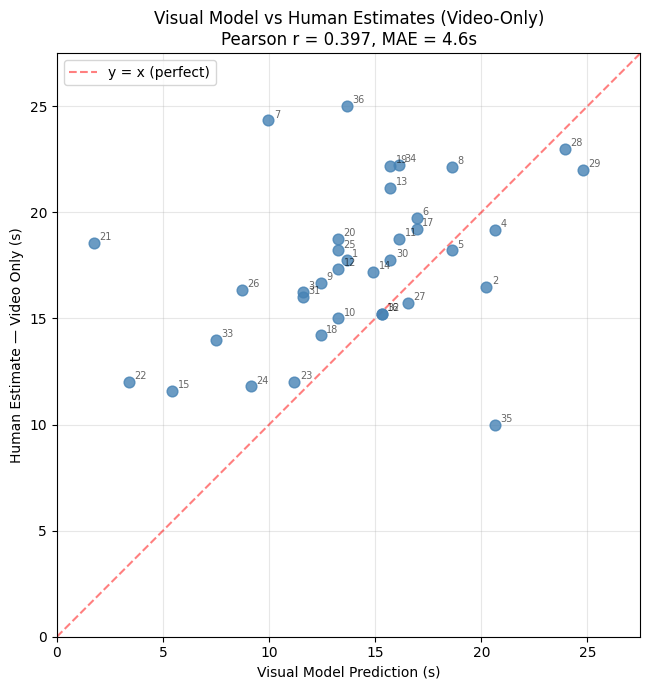

  Plot saved: D:\Sahil\Capstone_Project\results\visual\travel\visual_vs_human_video.png

  Clip   Actual (s)   Predicted (s)    Human (s)    Error (s)
------------------------------------------------------------
    24         16.1            9.14        11.80        -2.66
    22         17.1            3.38        12.00        -8.62
    31         17.4           11.60        16.00        -4.40
    15         17.7            5.43        11.60        -6.17
    23         18.7           11.19        12.00        -0.81
    20         19.2           13.25        18.75        -5.50
     9         19.2           12.43        16.67        -4.24
    21         19.8            1.73        18.56       -16.82
    14         20.2           14.89        17.20        -2.30
    33         20.3            7.49        14.00        -6.51
    27         20.6           16.54        15.71        +0.83
    30         21.7           15.72        17.75        -2.03
    12         21.8           13.25        1

In [8]:
# ============================================================================
# SECTION 8: Compare Visual Predictions Against Human Video-Only Estimates
# ============================================================================

from scipy.stats import pearsonr

# Path to human video-only estimates generated by generate_labels.py
VIDEO_LABELS_PATH = PROJECT_ROOT / "data" / "labels" / "video_perceived.csv"

if not VIDEO_LABELS_PATH.exists():
    print(f"Labels file not found: {VIDEO_LABELS_PATH}")
    print("Run generate_labels.py first to produce data/labels/video_perceived.csv")
else:
    labels_df = pd.read_csv(VIDEO_LABELS_PATH)

    # Normalise clip_id in both dataframes to plain integer string
    labels_df["clip_id"]      = labels_df["clip_id"].astype(str).str.strip()
    results_df["clip_id_str"] = results_df["clip_id"].astype(str).str.strip()

    merged = results_df.merge(labels_df[["clip_id", "perceived_s"]],
                              left_on="clip_id_str", right_on="clip_id", how="inner")

    if len(merged) == 0:
        print("No matching clips between predictions and human labels.")
    else:
        r   = pearsonr(merged["pred_perceived_s"], merged["perceived_s"])[0]
        mae = float(np.abs(merged["pred_perceived_s"] - merged["perceived_s"]).mean())
        bias = float((merged["pred_perceived_s"] - merged["perceived_s"]).mean())

        print("=" * 60)
        print("VISUAL MODEL vs HUMAN VIDEO-ONLY ESTIMATES")
        print("=" * 60)
        print(f"  Clips matched: {len(merged)}")
        print(f"  Pearson r:     {r:.3f}")
        print(f"  MAE:           {mae:.2f}s")
        print(f"  Mean bias:     {bias:+.2f}s  ({'overestimates' if bias > 0 else 'underestimates'})")

        # ── Scatter plot: predictions vs human estimates ──────────────────────
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.scatter(merged["pred_perceived_s"], merged["perceived_s"],
                   color="steelblue", alpha=0.8, s=60, zorder=3)

        for _, row in merged.iterrows():
            ax.annotate(str(row["clip_id_str"]),
                        (row["pred_perceived_s"], row["perceived_s"]),
                        fontsize=7, alpha=0.6, textcoords="offset points", xytext=(4, 2))

        all_vals = pd.concat([merged["pred_perceived_s"], merged["perceived_s"]])
        axis_max = all_vals.max() * 1.1
        ax.plot([0, axis_max], [0, axis_max], "r--", alpha=0.5, label="y = x (perfect)")
        ax.set_xlim(0, axis_max)
        ax.set_ylim(0, axis_max)
        ax.set_box_aspect(1)
        ax.set_xlabel("Visual Model Prediction (s)")
        ax.set_ylabel("Human Estimate — Video Only (s)")
        ax.set_title(f"Visual Model vs Human Estimates (Video-Only)\nPearson r = {r:.3f}, MAE = {mae:.1f}s")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUT_DIR / "visual_vs_human_video.png", dpi=150)
        plt.show()
        print(f"  Plot saved: {OUT_DIR / 'visual_vs_human_video.png'}")

        # ── Table: side by side comparison ───────────────────────────────────
        print()
        print(f"{'Clip':>6} {'Actual (s)':>12} {'Predicted (s)':>15} {'Human (s)':>12} {'Error (s)':>12}")
        print("-" * 60)
        for _, row in merged.sort_values("duration_s").iterrows():
            error = row["pred_perceived_s"] - row["perceived_s"]
            print(f"{row['clip_id_str']:>6} {row['duration_s']:>12.1f} "
                  f"{row['pred_perceived_s']:>15.2f} "
                  f"{row['perceived_s']:>12.2f} "
                  f"{error:>+12.2f}")
